# Lab 1 - Feed-Forward Neural Networks

Our answers are in [NOTES.md](NOTES.md); our runs are in [LOGBOOK.md](LOGBOOK.md).

## Task 1 - Preprocessing

### Imports

In [154]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### 1.1 - Dataset and class balance

In [155]:
df = pd.read_csv("Materiale/dataset_lab_1.csv")

print(df['Label'])

df['Label'].value_counts()

0             Benign
1             Benign
2             Benign
3             Benign
4             Benign
            ...     
31502    Brute Force
31503    Brute Force
31504    Brute Force
31505    Brute Force
31506    Brute Force
Name: Label, Length: 31507, dtype: str


Label
Benign         20000
DoS Hulk        5000
PortScan        5000
Brute Force     1507
Name: count, dtype: int64

### 1.2 - Cleaning

We retain 29,384 of 31,507 samples after removing missing values, duplicates, infinities and selected negative values.

(29384, 17)
0
0
Label
Benign         19240
PortScan        4849
DoS Hulk        3868
Brute Force     1427
Name: count, dtype: int64
0


Text(0.5, 1.0, 'Distribution of Flow Duration')

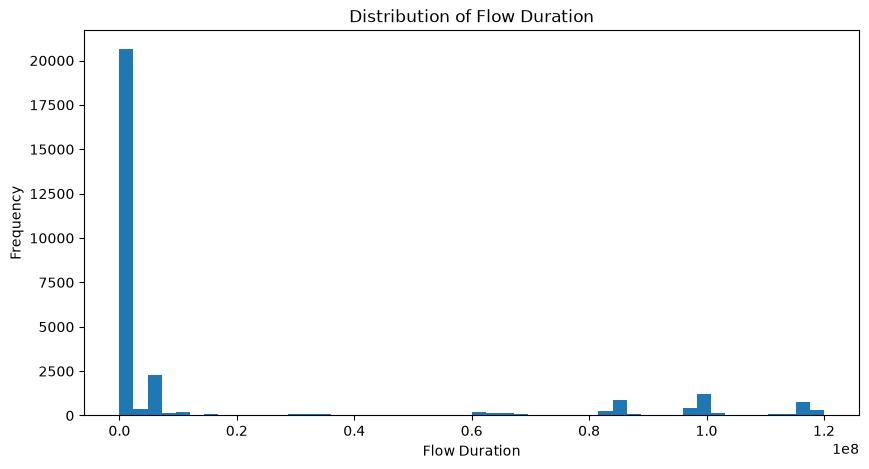

In [156]:
df = df.dropna()
df = df.drop_duplicates()
df["Label"].value_counts()
df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna()
cols_idx = [0, 1, 2, 3, 4, 7, 8, 9, 10, 11, 12, 14, 15]

cols = df.columns[cols_idx]

df = df[(df[cols] >= 0).all(axis=1)].copy()

print(df.shape)
print(df.isna().sum().sum())
print(df.duplicated().sum())
print(df["Label"].value_counts())
print(np.isinf(df.select_dtypes(include=np.number)).sum().sum())

plt.figure(figsize=(10, 5))

plt.hist(df["Flow Duration"], bins=50)

plt.xlabel("Flow Duration")
plt.ylabel("Frequency")
plt.title("Distribution of Flow Duration")

### 1.3 - Split and label encoding

We use a stratified 70/15/15 split with random_state=42 and fit the label encoder on training only.

In [157]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

X = df.drop(columns=["Label"])
Y = df["Label"]

print(df.shape)

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    Y,
    test_size=0.30,
    stratify=Y,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)
print(X_train.shape)
print(X_test.shape)
print(X_val.shape)

label_encoder = LabelEncoder()

y_train = label_encoder.fit_transform(y_train)
y_val = label_encoder.transform(y_val)
y_test = label_encoder.transform(y_test)

print("Classes:", label_encoder.classes_)
print(label_encoder.transform(label_encoder.classes_))

(29384, 17)
(20568, 16)
(4408, 16)
(4408, 16)
Classes: ['Benign' 'Brute Force' 'DoS Hulk' 'PortScan']
[0 1 2 3]


### 1.4 - Exploratory statistics

In [158]:
variances = X_train.var().sort_values(ascending=False)
print(variances)

print("\nFisher's Criterion")
scores = {}

for label in np.unique(y_train):

    X_class = X_train[y_train == label]
    X_rest  = X_train[y_train != label]

    mean_class = X_class.mean()
    mean_rest = X_rest.mean()

    var_class = X_class.var()
    var_rest = X_rest.var()

    fisher = (mean_class - mean_rest)**2 / (
        var_class + var_rest + 1e-9
    )

    scores[label] = fisher.mean()

scores = pd.Series(scores).sort_values()

print("0 = Benign, 1 = Brute Force, 2 = DoS Hulk, 3 = PortScan")
print(scores, "\n\nThe higher the score, the more discriminative the feature is for classification.")

Flow Duration             1.317755e+15
Flow Bytes/s              6.975741e+14
Fwd IAT Std               1.500167e+14
Flow IAT Mean             1.903953e+13
Flow Packets/s            3.648223e+10
Destination Port          3.104833e+08
Bwd Packet Length Max     4.038559e+06
Bwd Packet Length Mean    3.843754e+05
Fwd Packet Length Max     2.327037e+05
Packet Length Mean        8.741098e+04
Fwd Packet Length Mean    1.335118e+04
Subflow Fwd Packets       1.354483e+03
Total Fwd Packets         1.354483e+03
Down/Up Ratio             2.752730e-01
SYN Flag Count            3.890614e-02
Fwd PSH Flags             3.890614e-02
dtype: float64

Fisher's Criterion
0 = Benign, 1 = Brute Force, 2 = DoS Hulk, 3 = PortScan
0    0.092924
1    0.142394
3    0.170629
2    1.046245
dtype: float64 

The higher the score, the more discriminative the feature is for classification.


### 1.5 - Class proportions

In [159]:
print("\nTrain")

print(pd.Series(y_train).value_counts(normalize=True))

print("\nValidation")
print(pd.Series(y_val).value_counts(normalize=True))

print("\nTest")
print(pd.Series(y_test) .value_counts(normalize=True))


Train
0    0.654755
3    0.165014
2    0.131661
1    0.048571
Name: proportion, dtype: float64

Validation
0    0.654719
3    0.165154
2    0.131579
1    0.048548
Name: proportion, dtype: float64

Test
0    0.654946
3    0.164927
2    0.131579
1    0.048548
Name: proportion, dtype: float64


### 1.6 - StandardScaler

We fit on training only and reuse the scaler on validation/test.

In [160]:
from sklearn.preprocessing import StandardScaler

scaler_std = StandardScaler()

X_train_std = scaler_std.fit_transform(X_train)
X_val_std = scaler_std.transform(X_val)
X_test_std = scaler_std.transform(X_test)

### 1.7 - Alternative: log1p(Flow Duration) + StandardScaler

In [161]:
import numpy as np
from sklearn.preprocessing import StandardScaler

X_train_log = X_train.copy()
X_val_log = X_val.copy()
X_test_log = X_test.copy()

X_train_log["Flow Duration"] = np.log1p(X_train_log["Flow Duration"])
X_val_log["Flow Duration"] = np.log1p(X_val_log["Flow Duration"])
X_test_log["Flow Duration"] = np.log1p(X_test_log["Flow Duration"])

scaler_log = StandardScaler()

X_train_log_scaled = scaler_log.fit_transform(X_train_log)
X_val_log_scaled = scaler_log.transform(X_val_log)
X_test_log_scaled = scaler_log.transform(X_test_log)

### 1.8 - Scaling comparison

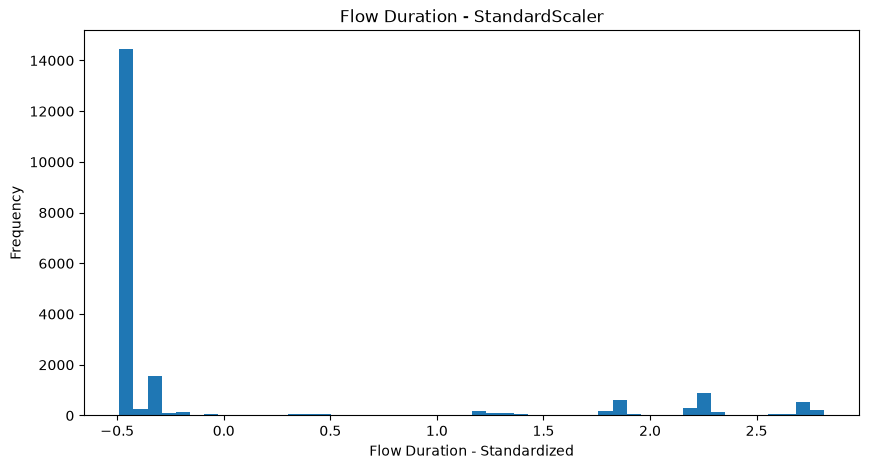

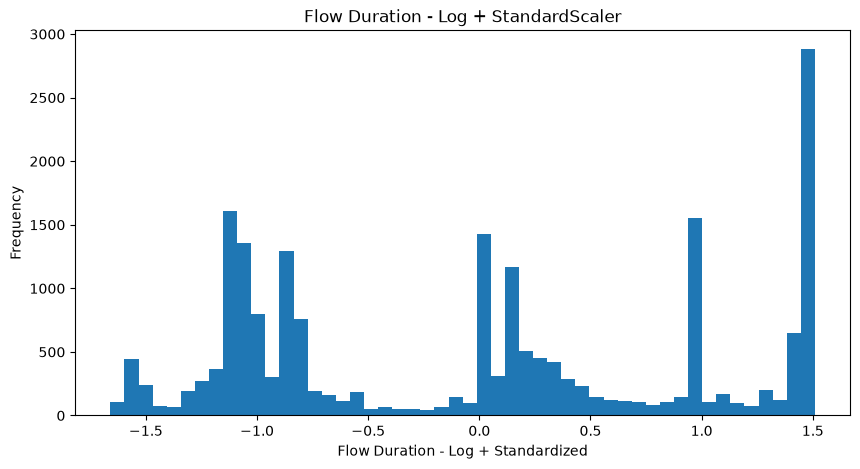

In [162]:
import matplotlib.pyplot as plt

flow_idx = X_train.columns.get_loc("Flow Duration")

plt.figure(figsize=(10, 5))
plt.hist(X_train_std[:, flow_idx], bins=50)
plt.xlabel("Flow Duration - Standardized")
plt.ylabel("Frequency")
plt.title("Flow Duration - StandardScaler")
plt.show()

plt.figure(figsize=(10, 5))
plt.hist(X_train_log_scaled[:, flow_idx], bins=50)
plt.xlabel("Flow Duration - Log + Standardized")
plt.ylabel("Frequency")
plt.title("Flow Duration - Log + StandardScaler")
plt.show()

## Task 2A - Minimal classifier

Before training, we expect Brute Force to be hardest because it is rare, and DoS Hulk easier because its exploratory separability score is highest. We check this against the validation report.

We first used 100 epochs (historical run 1), then 150 epochs (run 2). The outputs below are run 2; both attempts are documented in NOTES.md and LOGBOOK.md.


In [163]:
import copy
import random
import time
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import classification_report, accuracy_score, f1_score

SEED = 42
HIDDEN_SIZE = 64
BATCH_SIZE = 64
LEARNING_RATE = 5e-4
WEIGHT_DECAY = 0.01
MAX_EPOCHS = 150  # Increased from 100 to 150 epochs
PATIENCE = 20
MIN_DELTA = 0.5e-4

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
device = torch.device("cpu")
print(f"Device: {device}; seed: {SEED}")

Device: cpu; seed: 42


### Model and data

In [164]:
class FFNN(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        return self.fc2(self.relu(self.fc1(x)))

train_dataset = TensorDataset(
    torch.tensor(X_train_std, dtype=torch.float32),
    torch.tensor(y_train, dtype=torch.long),
)
validation_dataset = TensorDataset(
    torch.tensor(X_val_std, dtype=torch.float32),
    torch.tensor(y_val, dtype=torch.long),
)
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
)
validation_loader = DataLoader(
    validation_dataset, batch_size=BATCH_SIZE, shuffle=False,
)

model = FFNN(X_train_std.shape[1], HIDDEN_SIZE, len(label_encoder.classes_)).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(
    model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY,
)
print(model)
print(f"Train samples: {len(train_dataset)}; validation samples: {len(validation_dataset)}")

FFNN(
  (fc1): Linear(in_features=16, out_features=64, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=64, out_features=4, bias=True)
)
Train samples: 20568; validation samples: 4408


### Training and early stopping

We restore the checkpoint with the lowest validation loss; min_delta controls patience.

In [165]:
def fit(model, optimizer, train_loader, validation_loader,
        max_epochs=150, patience=20, min_delta=5e-5, verbose=True, criterion=None):
    criterion = nn.CrossEntropyLoss() if criterion is None else criterion
    device = next(model.parameters()).device
    train_losses, val_losses = [], []
    best_val_loss = float("inf")
    patience_reference = float("inf")
    best_state = None
    best_epoch = 0
    epochs_without_improvement = 0
    training_start = time.perf_counter()

    for epoch in range(1, max_epochs + 1):
        model.train()
        train_loss = 0.0
        train_normalizer = 0.0
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(X_batch), y_batch)
            loss.backward()
            optimizer.step()
            batch_weight = len(y_batch) if criterion.weight is None else criterion.weight[y_batch].sum().item()
            train_loss += loss.item() * batch_weight
            train_normalizer += batch_weight
        train_loss /= train_normalizer

        model.eval()
        val_loss = 0.0
        val_normalizer = 0.0
        with torch.no_grad():
            for X_batch, y_batch in validation_loader:
                X_batch, y_batch = X_batch.to(device), y_batch.to(device)
                loss = criterion(model(X_batch), y_batch)
                batch_weight = len(y_batch) if criterion.weight is None else criterion.weight[y_batch].sum().item()
                val_loss += loss.item() * batch_weight
                val_normalizer += batch_weight
        val_loss /= val_normalizer
        train_losses.append(train_loss)
        val_losses.append(val_loss)

        if not np.isfinite(train_loss) or not np.isfinite(val_loss):
            print("Stopped: non-finite loss")
            break

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())

        if val_loss < patience_reference - min_delta:
            patience_reference = val_loss
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if verbose:
            print(f"Epoch {epoch:3d} | train CE {train_loss:.5f} | val CE {val_loss:.5f}")
        if epochs_without_improvement >= patience:
            print(f"Early stopping at epoch {epoch}")
            break

    training_seconds = time.perf_counter() - training_start
    if best_state is not None:
        model.load_state_dict(best_state)
    model.eval()
    if verbose:
        print(f"Restored epoch {best_epoch}: val CE={best_val_loss:.5f}")
        print(f"Training + epoch validation: {training_seconds:.2f} s")
    return dict(model=model, train=train_losses, val=val_losses,
                best_epoch=best_epoch, best_loss=best_val_loss,
                seconds=training_seconds)

In [166]:
baseline = fit(model, optimizer, train_loader, validation_loader,
               max_epochs=MAX_EPOCHS, patience=PATIENCE, min_delta=MIN_DELTA)
train_losses, val_losses = baseline["train"], baseline["val"]
best_epoch, best_val_loss = baseline["best_epoch"], baseline["best_loss"]
training_seconds = baseline["seconds"]

Epoch   1 | train CE 0.74733 | val CE 0.49031
Epoch   2 | train CE 0.40398 | val CE 0.34131
Epoch   3 | train CE 0.31045 | val CE 0.28211
Epoch   4 | train CE 0.26708 | val CE 0.26156
Epoch   5 | train CE 0.24384 | val CE 0.23353
Epoch   6 | train CE 0.22834 | val CE 0.22120
Epoch   7 | train CE 0.21710 | val CE 0.21154
Epoch   8 | train CE 0.20794 | val CE 0.20431
Epoch   9 | train CE 0.20040 | val CE 0.19660
Epoch  10 | train CE 0.19387 | val CE 0.19063
Epoch  11 | train CE 0.18793 | val CE 0.18552
Epoch  12 | train CE 0.18327 | val CE 0.18029
Epoch  13 | train CE 0.17885 | val CE 0.17647
Epoch  14 | train CE 0.17543 | val CE 0.17367
Epoch  15 | train CE 0.17235 | val CE 0.17071
Epoch  16 | train CE 0.16946 | val CE 0.16936
Epoch  17 | train CE 0.16713 | val CE 0.16746
Epoch  18 | train CE 0.16523 | val CE 0.16496
Epoch  19 | train CE 0.16338 | val CE 0.16400
Epoch  20 | train CE 0.16188 | val CE 0.16250
Epoch  21 | train CE 0.15990 | val CE 0.16216
Epoch  22 | train CE 0.15872 | val

### Loss curves

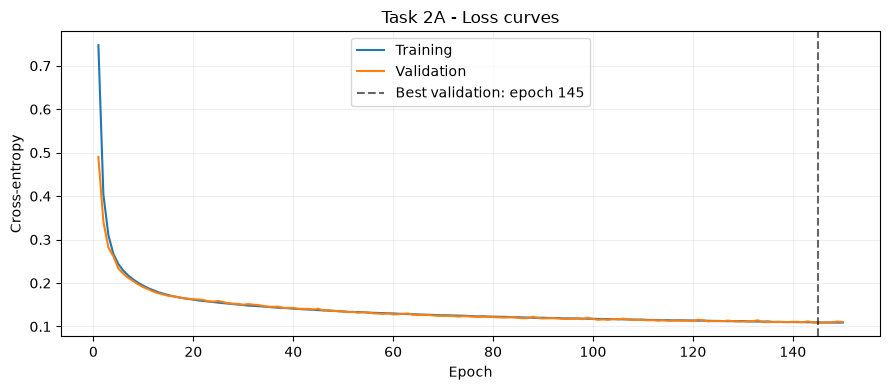

In [167]:
epochs = np.arange(1, len(train_losses) + 1)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(epochs, train_losses, label="Training")
ax.plot(epochs, val_losses, label="Validation")
ax.axvline(best_epoch, color="black", linestyle="--", alpha=0.6,
           label=f"Best validation: epoch {best_epoch}")
ax.set(xlabel="Epoch", ylabel="Cross-entropy", title="Task 2A - Loss curves")
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

### Validation report

In [168]:
val_predictions = []
restored_val_loss = 0.0
with torch.no_grad():
    for X_batch, y_batch in validation_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        logits = model(X_batch)
        restored_val_loss += criterion(logits, y_batch).item() * len(y_batch)
        val_predictions.extend(logits.argmax(dim=1).cpu().tolist())
restored_val_loss /= len(validation_dataset)

class_names = label_encoder.classes_.tolist()
class_ids = list(range(len(class_names)))
val_report = classification_report(
    y_val, val_predictions, labels=class_ids, target_names=class_names,
    output_dict=True, zero_division=0,
)
val_accuracy = accuracy_score(y_val, val_predictions)
val_macro_f1 = f1_score(y_val, val_predictions, labels=class_ids, average="macro")
print(classification_report(
    y_val, val_predictions, labels=class_ids, target_names=class_names,
    digits=4, zero_division=0,
))
print(f"Validation accuracy: {val_accuracy:.4f}; macro-F1: {val_macro_f1:.4f}")
assert np.isclose(restored_val_loss, best_val_loss, rtol=1e-6, atol=1e-8)

              precision    recall  f1-score   support

      Benign     0.9663    0.9740    0.9701      2886
 Brute Force     0.8089    0.9299    0.8652       214
    DoS Hulk     0.9907    0.9207    0.9544       580
    PortScan     0.9496    0.9313    0.9404       728

    accuracy                         0.9578      4408
   macro avg     0.9289    0.9390    0.9325      4408
weighted avg     0.9591    0.9578    0.9581      4408

Validation accuracy: 0.9578; macro-F1: 0.9325


## Task 2B - Fundamentals

We change only scaling (S1) or LR (S2/S3), using fresh models and the same seed.

Before training, we expect unstable losses for S1, oscillation for S2 and slow learning for S3. Our predicted severity is S2 > S1 > S3.

In [169]:
def run_variant(train_x, val_x, lr):
    random.seed(42)
    np.random.seed(42)
    torch.manual_seed(42)
    def loader(x, y, shuffle):
        data = TensorDataset(torch.tensor(np.asarray(x), dtype=torch.float32),
                             torch.tensor(y, dtype=torch.long))
        return DataLoader(data, batch_size=64, shuffle=shuffle,
                          generator=torch.Generator().manual_seed(42))
    candidate = FFNN(16, 64, 4).to(device)
    opt = torch.optim.AdamW(candidate.parameters(), lr=lr, weight_decay=0.01)
    result = fit(candidate, opt, loader(train_x, y_train, True),
                 loader(val_x, y_val, False), verbose=False)
    if result["best_epoch"] == 0:
        return dict(result, accuracy=np.nan, macro_f1=np.nan)
    with torch.no_grad():
        predictions = candidate(torch.tensor(np.asarray(val_x), dtype=torch.float32,
                                             device=device)).argmax(1).cpu().numpy()
    result["accuracy"] = accuracy_score(y_val, predictions)
    result["macro_f1"] = f1_score(y_val, predictions, labels=range(4), average="macro", zero_division=0)
    return result

In [170]:
variants = {
    "S1 - raw inputs": (X_train, X_val, 5e-4),
    "S2 - high LR": (X_train_std, X_val_std, 0.5),
    "S3 - low LR": (X_train_std, X_val_std, 5e-6),
}
results_2b = {name: run_variant(*settings) for name, settings in variants.items()}

Early stopping at epoch 35
Early stopping at epoch 33


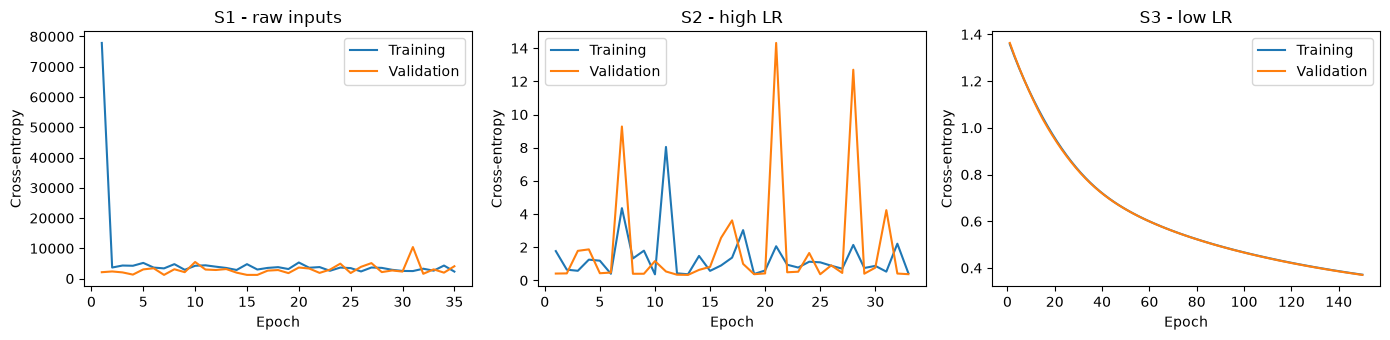

,Val loss,Accuracy,Macro-F1,Epochs,Best epoch,Train + val s
S1 - raw inputs,1218.416544,0.932623,0.893079,35.0,15.0,9.052830
S2 - high LR,0.333414,0.936252,0.895317,33.0,13.0,8.568939
S3 - low LR,0.370412,0.900408,0.739091,150.0,150.0,38.410118


In [171]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, (name, result) in zip(axes, results_2b.items()):
    epochs = np.arange(1, len(result["train"]) + 1)
    ax.plot(epochs, result["train"], label="Training")
    ax.plot(epochs, result["val"], label="Validation")
    ax.set(title=name, xlabel="Epoch", ylabel="Cross-entropy")
    ax.legend()
fig.tight_layout()
plt.show()

pd.DataFrame({name: {"Val loss": r["best_loss"], "Accuracy": r["accuracy"],
                    "Macro-F1": r["macro_f1"], "Epochs": len(r["train"]),
                    "Best epoch": r["best_epoch"], "Train + val s": r["seconds"]}
              for name, r in results_2b.items()}).T

## Task 2C - Lock in our baseline

We tune the settings below on validation. Before the activation comparison, we expect ReLU to outperform Linear, especially on the harder classes. Both use the same initial weights and hyperparameters.

We select by validation macro-F1; each run restores its minimum-validation-loss checkpoint. Linear uses Identity between the two linear layers.

Our selected baseline is run 7: ReLU, lr=1e-3 and weight_decay=0.005 (best validation checkpoint: epoch 196).


In [172]:
HP_2C = dict(
    hidden_size=64,
    batch_size=64,
    lr=1e-3,  # Increased from 5e-4 to 1e-3
    weight_decay=0.005,  # Reduced from 0.01 to 0.005
    max_epochs=200,
    patience=20,
    min_delta=5e-5,
    seed=42,
)
print(pd.Series(HP_2C, name="Task 2C hyperparameters").to_string())

hidden_size      64.00000
batch_size       64.00000
lr                0.00100
weight_decay      0.00500
max_epochs      200.00000
patience         20.00000
min_delta         0.00005
seed             42.00000


In [173]:
def plot_confusion_2c(matrices, titles):
    names = label_encoder.classes_.tolist()
    fig, axes = plt.subplots(1, len(matrices), figsize=(6 * len(matrices), 5),
                             squeeze=False, layout="constrained")
    for ax, matrix, title in zip(axes.ravel(), matrices, titles):
        totals = matrix.sum(axis=1, keepdims=True)
        percentages = np.divide(100.0 * matrix, totals,
                                out=np.zeros_like(matrix, dtype=float), where=totals != 0)
        image = ax.imshow(percentages, cmap="Blues", vmin=0, vmax=100)
        ax.set(xticks=range(len(names)), yticks=range(len(names)),
               xticklabels=names, yticklabels=names,
               xlabel="Predicted class", ylabel="Actual class", title=title)
        plt.setp(ax.get_xticklabels(), rotation=25, ha="right")
        ax.set_xticks(np.arange(len(names) + 1) - 0.5, minor=True)
        ax.set_yticks(np.arange(len(names) + 1) - 0.5, minor=True)
        ax.grid(which="minor", color="white", linewidth=2)
        ax.tick_params(which="minor", bottom=False, left=False)
        for i in range(len(names)):
            for j in range(len(names)):
                ax.text(j, i, f"{matrix[i, j]:,}\n{percentages[i, j]:.1f}%",
                        ha="center", va="center", fontsize=10,
                        color="white" if percentages[i, j] > 50 else "#16324f")
    fig.colorbar(image, ax=axes.ravel().tolist(), label="% of actual class", shrink=0.8)
    fig.suptitle("Confusion matrices - count and row percentage", fontsize=14)
    plt.show()

In [174]:
def train_2c(activation, **overrides):
    hp = {**HP_2C, **overrides}
    random.seed(hp["seed"])
    np.random.seed(hp["seed"])
    torch.manual_seed(hp["seed"])
    def loader(x, y, shuffle):
        data = TensorDataset(torch.tensor(np.asarray(x), dtype=torch.float32),
                             torch.tensor(y, dtype=torch.long))
        return DataLoader(data, batch_size=hp["batch_size"], shuffle=shuffle,
                          generator=torch.Generator().manual_seed(hp["seed"]))
    candidate = nn.Sequential(
        nn.Linear(X_train_std.shape[1], hp["hidden_size"]),
        nn.ReLU() if activation == "ReLU" else nn.Identity(),
        nn.Linear(hp["hidden_size"], len(label_encoder.classes_)),
    ).to(device)
    optimizer = torch.optim.AdamW(candidate.parameters(), lr=hp["lr"],
                                 weight_decay=hp["weight_decay"])
    result = fit(candidate, optimizer, loader(X_train_std, y_train, True),
                 loader(X_val_std, y_val, False), max_epochs=hp["max_epochs"],
                 patience=hp["patience"], min_delta=hp["min_delta"], verbose=False)
    if result["best_epoch"] == 0:
        raise RuntimeError(f"{activation}: no finite checkpoint; we cannot select this run")
    return result

def evaluate_2c(model, x, y, title):
    from sklearn.metrics import confusion_matrix
    model.eval()
    with torch.no_grad():
        logits = model(torch.tensor(np.asarray(x), dtype=torch.float32,
                                    device=next(model.parameters()).device))
        loss = nn.functional.cross_entropy(
            logits, torch.tensor(y, dtype=torch.long, device=logits.device)).item()
        predictions = logits.argmax(1).cpu().numpy()
    names = label_encoder.classes_.tolist()
    labels = list(range(len(names)))
    report = classification_report(y, predictions, labels=labels, target_names=names,
                                   output_dict=True, zero_division=0)
    matrix = confusion_matrix(y, predictions, labels=labels)
    metrics = dict(loss=loss, accuracy=accuracy_score(y, predictions),
                   macro_precision=report["macro avg"]["precision"],
                   macro_recall=report["macro avg"]["recall"],
                   macro_f1=report["macro avg"]["f1-score"],
                   weighted_f1=report["weighted avg"]["f1-score"])
    print(f"\n{title}")
    print(classification_report(y, predictions, labels=labels, target_names=names,
                                digits=4, zero_division=0))
    print(pd.Series(metrics).round(5).to_string())
    return dict(metrics=metrics, report=report, predictions=predictions,
                confusion_matrix=matrix)

### ReLU versus Linear - validation

Early stopping at epoch 75

ReLU - validation
              precision    recall  f1-score   support

      Benign     0.9716    0.9844    0.9780      2886
 Brute Force     0.9132    0.9346    0.9238       214
    DoS Hulk     0.9665    0.9448    0.9555       580
    PortScan     0.9685    0.9286    0.9481       728

    accuracy                         0.9676      4408
   macro avg     0.9550    0.9481    0.9513      4408
weighted avg     0.9676    0.9676    0.9675      4408

loss               0.08986
accuracy           0.96756
macro_precision    0.95496
macro_recall       0.94810
macro_f1           0.95135
weighted_f1        0.96746

Linear - validation
              precision    recall  f1-score   support

      Benign     0.9472    0.9321    0.9396      2886
 Brute Force     0.8071    0.7430    0.7737       214
    DoS Hulk     0.9941    0.8672    0.9263       580
    PortScan     0.7827    0.9299    0.8500       728

    accuracy                         0.9140      4408
   macro a

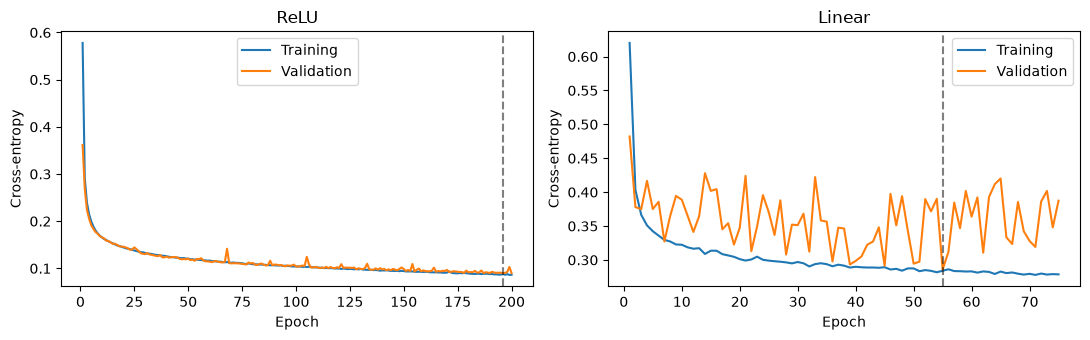


Per-class validation comparison
             ReLU precision  ReLU recall  ReLU f1-score  Linear precision  Linear recall  Linear f1-score
Benign               0.9716       0.9844         0.9780            0.9472         0.9321           0.9396
Brute Force          0.9132       0.9346         0.9238            0.8071         0.7430           0.7737
DoS Hulk             0.9665       0.9448         0.9555            0.9941         0.8672           0.9263
PortScan             0.9685       0.9286         0.9481            0.7827         0.9299           0.8500


In [175]:
results_2c = {name: train_2c(name) for name in ("ReLU", "Linear")}
validation_2c = {name: evaluate_2c(result["model"], X_val_std, y_val,
                                 f"{name} - validation")
                 for name, result in results_2c.items()}

summary_2c = pd.DataFrame({
    name: dict(validation_2c[name]["metrics"], epochs=len(result["train"]),
               best_epoch=result["best_epoch"], train_val_s=result["seconds"])
    for name, result in results_2c.items()
}).T
print("\nValidation comparison")
print(summary_2c.round(5).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, (name, result) in zip(axes, results_2c.items()):
    epochs = np.arange(1, len(result["train"]) + 1)
    ax.plot(epochs, result["train"], label="Training")
    ax.plot(epochs, result["val"], label="Validation")
    ax.axvline(result["best_epoch"], color="black", linestyle="--", alpha=0.5)
    ax.set(title=name, xlabel="Epoch", ylabel="Cross-entropy")
    ax.legend()
fig.tight_layout()
plt.show()

per_class_2c = pd.DataFrame({
    f"{name} {metric}": {cls: result["report"][cls][metric]
                         for cls in label_encoder.classes_}
    for name, result in validation_2c.items()
    for metric in ("precision", "recall", "f1-score")
})
print("\nPer-class validation comparison")
print(per_class_2c.round(4).to_string())

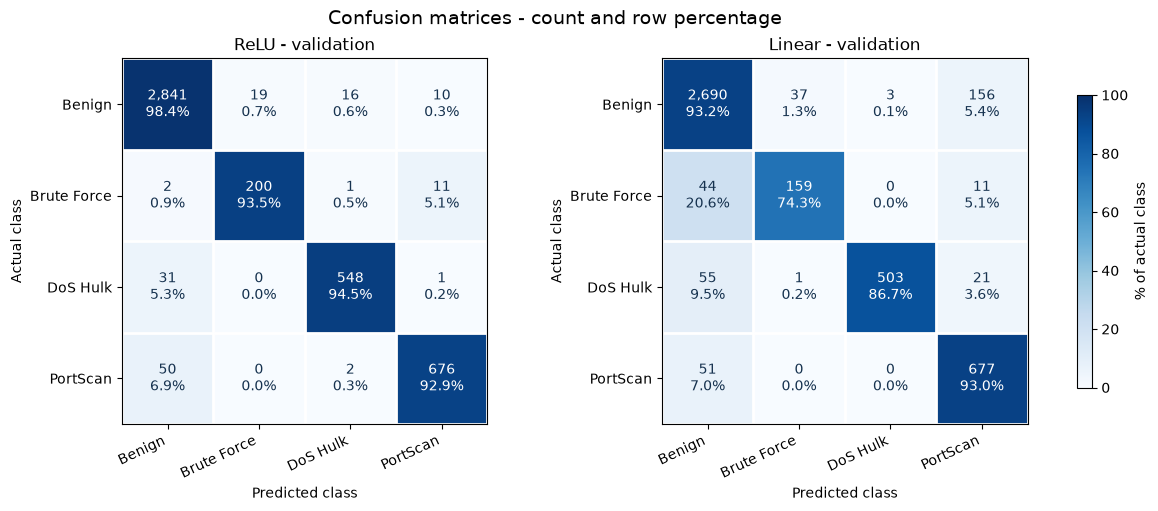

In [176]:
plot_confusion_2c(
    [result["confusion_matrix"] for result in validation_2c.values()],
    [f"{name} - validation" for name in validation_2c],
)

In [177]:
selected_activation_2c = max(
    validation_2c, key=lambda name: validation_2c[name]["metrics"]["macro_f1"])
baseline_2c = results_2c[selected_activation_2c]["model"]
locked_hp_2c = copy.deepcopy(HP_2C)
baseline_scaler_2c = copy.deepcopy(scaler_std)
baseline_classes_2c = label_encoder.classes_.copy()
baseline_features_2c = X_train.columns.tolist()
print(f"Our locked baseline: {selected_activation_2c}")
print(f"Validation macro-F1: {validation_2c[selected_activation_2c]['metrics']['macro_f1']:.4f}")

Our locked baseline: ReLU
Validation macro-F1: 0.9513


### Locked baseline - test

We evaluate test after fixing the hyperparameters and activation. We do not use test scores to select or retune the model.

In [178]:
test_2c = evaluate_2c(baseline_2c, X_test_std, y_test,
                      f"Locked {selected_activation_2c} baseline - test")
generalization_2c = pd.DataFrame({
    "Validation": validation_2c[selected_activation_2c]["metrics"],
    "Test": test_2c["metrics"],
}).T
print("\nOur locked baseline - generalization")
print(generalization_2c.round(5).to_string())
for metric in ("accuracy", "macro_f1"):
    gap = test_2c["metrics"][metric] - validation_2c[selected_activation_2c]["metrics"][metric]
    print(f"Test - validation {metric}: {gap:+.4f} ({100 * gap:+.2f} percentage points)")

print("\nPer-class F1: validation versus test")
print(pd.DataFrame({
    "Validation F1": {cls: validation_2c[selected_activation_2c]["report"][cls]["f1-score"]
                      for cls in baseline_classes_2c},
    "Test F1": {cls: test_2c["report"][cls]["f1-score"] for cls in baseline_classes_2c},
}).round(4).to_string())


Locked ReLU baseline - test
              precision    recall  f1-score   support

      Benign     0.9732    0.9813    0.9772      2887
 Brute Force     0.9156    0.9626    0.9385       214
    DoS Hulk     0.9701    0.9517    0.9608       580
    PortScan     0.9602    0.9285    0.9441       727

    accuracy                         0.9678      4408
   macro avg     0.9548    0.9560    0.9552      4408
weighted avg     0.9679    0.9678    0.9677      4408

loss               0.08612
accuracy           0.96779
macro_precision    0.95476
macro_recall       0.95603
macro_f1           0.95516
weighted_f1        0.96772

Our locked baseline - generalization
               loss  accuracy  macro_precision  macro_recall  macro_f1  weighted_f1
Validation  0.08986   0.96756          0.95496       0.94810   0.95135      0.96746
Test        0.08612   0.96779          0.95476       0.95603   0.95516      0.96772
Test - validation accuracy: +0.0002 (+0.02 percentage points)
Test - validation macr

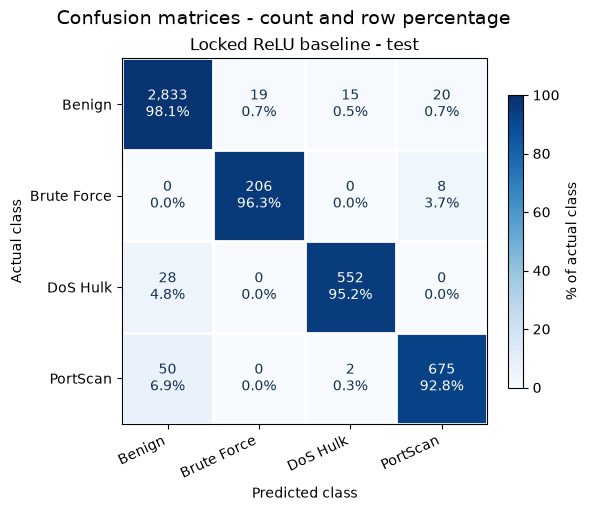

In [179]:
plot_confusion_2c([test_2c["confusion_matrix"]],
                  [f"Locked {selected_activation_2c} baseline - test"])

## Task 3 - Destination Port bias

We think our model may have learned that Brute Force uses port 80 in this dataset. This is a dataset artefact, not a general property of brute-force attacks. Before inference, we expect Brute Force recall to fall when we change its test destination port to 8080.

We use our trained Task 2C baseline (run 7) and its fitted scaler. We change only Brute Force test flows; no training or fitting is performed.

In [180]:
required_3 = ("baseline_2c", "baseline_scaler_2c", "baseline_classes_2c", "baseline_features_2c")
if any(name not in globals() for name in required_3):
    raise RuntimeError("Task 3 needs the already-trained Task 2C baseline in this session; no retraining is performed here.")
np.testing.assert_array_equal(label_encoder.classes_, baseline_classes_2c)

brute_force_id_3 = np.flatnonzero(baseline_classes_2c == "Brute Force").item()
brute_force_mask_3 = np.asarray(y_test) == brute_force_id_3
X_test_original_3 = X_test.loc[:, baseline_features_2c].copy()
X_test_8080 = X_test_original_3.copy()
assert brute_force_mask_3.any()
assert X_test_original_3.loc[brute_force_mask_3, "Destination Port"].eq(80).all()

X_test_8080.loc[brute_force_mask_3, "Destination Port"] = 8080
X_test_original_std_3 = baseline_scaler_2c.transform(X_test_original_3)
X_test_8080_std = baseline_scaler_2c.transform(X_test_8080)
assert X_test_8080.drop(columns="Destination Port").equals(X_test_original_3.drop(columns="Destination Port"))
assert X_test_8080.loc[~brute_force_mask_3].equals(X_test_original_3.loc[~brute_force_mask_3])
print(f"Changed Destination Port 80 -> 8080 for {brute_force_mask_3.sum()} Brute Force test flows only.")

Changed Destination Port 80 -> 8080 for 214 Brute Force test flows only.


In [181]:
weights_before_3 = {name: value.detach().clone() for name, value in baseline_2c.state_dict().items()}
original_test_3 = evaluate_2c(baseline_2c, X_test_original_std_3, y_test, "Task 3 - original test")
counterfactual_3 = evaluate_2c(baseline_2c, X_test_8080_std, y_test, "Task 3 - Brute Force port 8080")

assert all(torch.equal(weights_before_3[name], value) for name, value in baseline_2c.state_dict().items())
np.testing.assert_array_equal(original_test_3["predictions"][~brute_force_mask_3],
                              counterfactual_3["predictions"][~brute_force_mask_3])
assert X_test.loc[:, baseline_features_2c].equals(X_test_original_3)

comparison_3 = pd.DataFrame({"Original test": original_test_3["metrics"],
                             "Brute Force port 8080": counterfactual_3["metrics"]}).T
print("\nOriginal versus counterfactual test")
print(comparison_3.round(5).to_string())
original_recall_3 = original_test_3["report"]["Brute Force"]["recall"]
counterfactual_recall_3 = counterfactual_3["report"]["Brute Force"]["recall"]
print(f"Brute Force recall: {original_recall_3:.4f} -> {counterfactual_recall_3:.4f}")
print(f"Recall change: {100 * (counterfactual_recall_3 - original_recall_3):+.2f} percentage points")
changed_predictions_3 = np.count_nonzero(original_test_3["predictions"] != counterfactual_3["predictions"])
print(f"Changed predictions: {changed_predictions_3}; model weights and original test inputs unchanged.")


Task 3 - original test
              precision    recall  f1-score   support

      Benign     0.9732    0.9813    0.9772      2887
 Brute Force     0.9156    0.9626    0.9385       214
    DoS Hulk     0.9701    0.9517    0.9608       580
    PortScan     0.9602    0.9285    0.9441       727

    accuracy                         0.9678      4408
   macro avg     0.9548    0.9560    0.9552      4408
weighted avg     0.9679    0.9678    0.9677      4408

loss               0.08612
accuracy           0.96779
macro_precision    0.95476
macro_recall       0.95603
macro_f1           0.95516
weighted_f1        0.96772

Task 3 - Brute Force port 8080
              precision    recall  f1-score   support

      Benign     0.9112    0.9813    0.9450      2887
 Brute Force     0.2963    0.0374    0.0664       214
    DoS Hulk     0.9701    0.9517    0.9608       580
    PortScan     0.9602    0.9285    0.9441       727

    accuracy                         0.9229      4408
   macro avg     0.78

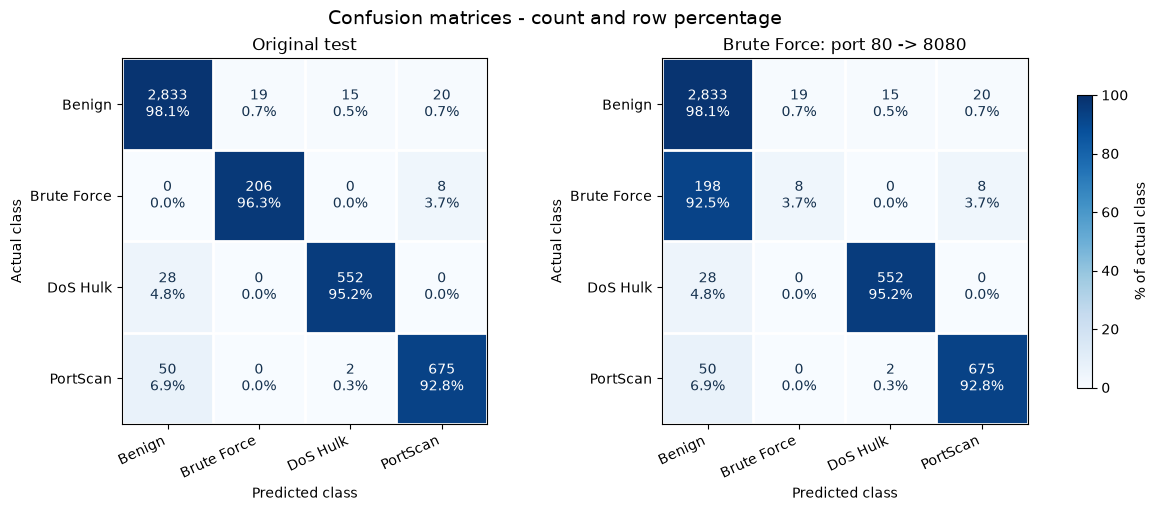

In [182]:
plot_confusion_2c(
    [original_test_3["confusion_matrix"], counterfactual_3["confusion_matrix"]],
    ["Original test", "Brute Force: port 80 -> 8080"],
)

### Our result

Our prediction holds: Brute Force recall falls from 0.9626 (206/214) to 0.0374 (8/214). The 198 changed predictions become Benign; non-Brute-Force predictions and model weights stay unchanged. This supports heavy reliance on the port-80 shortcut rather than port-independent detection. Macro-F1 drops from 0.95516 to 0.72906; the full interpretation is in NOTES.md.

## Task 3B - Port-free preprocessing

We remove Destination Port from the original CSV, then repeat cleaning, stratified splitting and scaling. We keep deduplication to avoid repeating identical labelled feature vectors across partitions. The class counts and our reasoning are in NOTES.md.

In [183]:
import pandas as pd
import numpy as np

raw_3b = pd.read_csv("Materiale/dataset_lab_1.csv")
nonnegative_3b = [
    "Flow Duration", "Flow IAT Mean", "Fwd PSH Flags", "Bwd Packet Length Mean",
    "Bwd Packet Length Max", "SYN Flag Count", "Fwd Packet Length Mean",
    "Fwd IAT Std", "Packet Length Mean", "Fwd Packet Length Max",
    "Subflow Fwd Packets", "Total Fwd Packets", "Destination Port",
]

def clean_3b(frame):
    frame = frame.dropna().drop_duplicates()
    frame = frame.replace([np.inf, -np.inf], np.nan).dropna()
    columns = [name for name in nonnegative_3b if name in frame.columns]
    return frame.loc[(frame[columns] >= 0).all(axis=1)].copy()

with_port_3b = clean_3b(raw_3b)
# Remove the port from the original data BEFORE deduplication.
df_3b = clean_3b(raw_3b.drop(columns="Destination Port"))
class_counts_3b = pd.DataFrame({
    "With port": with_port_3b["Label"].value_counts(),
    "Without port": df_3b["Label"].value_counts(),
}).sort_index()
class_counts_3b["Removed"] = class_counts_3b["With port"] - class_counts_3b["Without port"]
class_counts_3b["Removed %"] = 100 * class_counts_3b["Removed"] / class_counts_3b["With port"]
class_counts_3b["New share %"] = 100 * class_counts_3b["Without port"] / len(df_3b)
print(class_counts_3b.round(2).to_string())
print(f"Clean samples: {len(with_port_3b)} -> {len(df_3b)}")
print(f"Rarest class: {df_3b['Label'].value_counts().idxmin()}")

             With port  Without port  Removed  Removed %  New share %
Label                                                                
Benign           19240         16888     2352      12.22        75.16
Brute Force       1427          1427        0       0.00         6.35
DoS Hulk          3868          3868        0       0.00        17.22
PortScan          4849           285     4564      94.12         1.27
Clean samples: 29384 -> 22468
Rarest class: PortScan


### New split and scaler

We retain the 70/15/15 stratified split and seed 42. We fit a new label encoder and StandardScaler on training only. We use these 15-feature arrays (`X_train_std_3b`, `X_val_std_3b`, `X_test_std_3b`) and their labels for the rest of the lab.

In [184]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

X_3b = df_3b.drop(columns="Label")
y_3b = df_3b["Label"]
X_train_3b, X_temp_3b, y_train_text_3b, y_temp_3b = train_test_split(
    X_3b, y_3b, test_size=0.30, stratify=y_3b, random_state=42,
)
X_val_3b, X_test_3b, y_val_text_3b, y_test_text_3b = train_test_split(
    X_temp_3b, y_temp_3b, test_size=0.50, stratify=y_temp_3b, random_state=42,
)
label_encoder_3b = LabelEncoder()
y_train_3b = label_encoder_3b.fit_transform(y_train_text_3b)
y_val_3b = label_encoder_3b.transform(y_val_text_3b)
y_test_3b = label_encoder_3b.transform(y_test_text_3b)

scaler_3b = StandardScaler()
X_train_std_3b = scaler_3b.fit_transform(X_train_3b)
X_val_std_3b = scaler_3b.transform(X_val_3b)
X_test_std_3b = scaler_3b.transform(X_test_3b)

split_counts_3b = pd.DataFrame({
    "Train": y_train_text_3b.value_counts(),
    "Validation": y_val_text_3b.value_counts(),
    "Test": y_test_text_3b.value_counts(),
}).sort_index()
print(split_counts_3b.to_string())
print(f"Shapes: train {X_train_std_3b.shape}, validation {X_val_std_3b.shape}, test {X_test_std_3b.shape}")
print("Classes:", label_encoder_3b.classes_)
assert "Destination Port" not in X_3b.columns and X_3b.shape[1] == 15
assert not df_3b.duplicated().any()
assert set(X_train_3b.index).isdisjoint(X_val_3b.index)
assert set(X_train_3b.index).isdisjoint(X_test_3b.index)
assert set(X_val_3b.index).isdisjoint(X_test_3b.index)
assert sum(map(len, (X_train_3b, X_val_3b, X_test_3b))) == len(df_3b)
assert all(np.isfinite(x).all() for x in (X_train_std_3b, X_val_std_3b, X_test_std_3b))
assert scaler_3b.n_samples_seen_ == len(X_train_3b)
np.testing.assert_allclose(scaler_3b.mean_, X_train_3b.mean().to_numpy())

             Train  Validation  Test
Label                               
Benign       11821        2533  2534
Brute Force    999         214   214
DoS Hulk      2708         580   580
PortScan       199          43    43
Shapes: train (15727, 15), validation (3370, 15), test (3371, 15)
Classes: ['Benign' 'Brute Force' 'DoS Hulk' 'PortScan']


## Task 4 - The rare class: loss and imbalance

### Our prediction before training

We expect **PortScan** to be hardest: after removing the port and deduplicating, only 199 training samples remain. With so few examples and an unweighted loss dominated by larger classes, the model may struggle to learn reliable PortScan boundaries. We will check per-class F1 and recall.

We retrain our Task 2C configuration from scratch on the 15-feature data, using ordinary cross-entropy. We evaluate validation only.

In [185]:
HP_4 = HP_2C.copy()
print(pd.Series(HP_4, name="Port-free baseline hyperparameters").to_string())
print("Architecture: 15 -> 64 -> 4, ReLU; unweighted cross-entropy")
print("Training support:")
print(pd.Series(label_encoder_3b.inverse_transform(y_train_3b)).value_counts().to_string())

hidden_size      64.00000
batch_size       64.00000
lr                0.00100
weight_decay      0.00500
max_epochs      200.00000
patience         20.00000
min_delta         0.00005
seed             42.00000
Architecture: 15 -> 64 -> 4, ReLU; unweighted cross-entropy
Training support:
Benign         11821
DoS Hulk        2708
Brute Force      999
PortScan         199


In [186]:
random.seed(HP_4["seed"])
np.random.seed(HP_4["seed"])
torch.manual_seed(HP_4["seed"])
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
device_4 = torch.device("cpu")
np.testing.assert_array_equal(label_encoder_3b.classes_, label_encoder.classes_)

train_loader_4 = DataLoader(
    TensorDataset(torch.tensor(X_train_std_3b, dtype=torch.float32),
                  torch.tensor(y_train_3b, dtype=torch.long)),
    batch_size=HP_4["batch_size"], shuffle=True,
    generator=torch.Generator().manual_seed(HP_4["seed"]),
)
val_loader_4 = DataLoader(
    TensorDataset(torch.tensor(X_val_std_3b, dtype=torch.float32),
                  torch.tensor(y_val_3b, dtype=torch.long)),
    batch_size=HP_4["batch_size"], shuffle=False,
    generator=torch.Generator().manual_seed(HP_4["seed"]),
)
baseline_portfree_4 = nn.Sequential(
    nn.Linear(X_train_std_3b.shape[1], HP_4["hidden_size"]), nn.ReLU(),
    nn.Linear(HP_4["hidden_size"], len(label_encoder_3b.classes_)),
).to(device_4)
optimizer_4 = torch.optim.AdamW(baseline_portfree_4.parameters(),
                              lr=HP_4["lr"], weight_decay=HP_4["weight_decay"])
result_4 = fit(baseline_portfree_4, optimizer_4, train_loader_4, val_loader_4,
               max_epochs=HP_4["max_epochs"], patience=HP_4["patience"],
               min_delta=HP_4["min_delta"], verbose=False)
if result_4["best_epoch"] == 0:
    raise RuntimeError("No finite validation checkpoint for the port-free baseline")
print(f"Epochs: {len(result_4['train'])}; best epoch: {result_4['best_epoch']}")
print(f"Best validation CE: {result_4['best_loss']:.5f}")
print(f"Training + epoch validation: {result_4['seconds']:.2f} s")

Early stopping at epoch 149
Epochs: 149; best epoch: 129
Best validation CE: 0.10506
Training + epoch validation: 30.14 s


In [187]:
validation_4 = evaluate_2c(baseline_portfree_4, X_val_std_3b, y_val_3b,
                            "Task 4 - port-free baseline, validation")
portscan_id_4 = np.flatnonzero(label_encoder_3b.classes_ == "PortScan").item()
portscan_detected_4 = int(validation_4["confusion_matrix"][portscan_id_4, portscan_id_4])
portscan_support_4 = int(validation_4["report"]["PortScan"]["support"])
hardest_class_4 = min(label_encoder_3b.classes_,
                      key=lambda name: validation_4["report"][name]["f1-score"])
print(f"\nPortScan detected: {portscan_detected_4}/{portscan_support_4}")
print(f"PortScan recall: {validation_4['report']['PortScan']['recall']:.4f}")
print(f"Lowest per-class F1: {hardest_class_4}")
print("Our hardest-class prediction:", "confirmed" if hardest_class_4 == "PortScan" else "revised")
assert np.isclose(validation_4["metrics"]["loss"], result_4["best_loss"], rtol=1e-5, atol=1e-7)


Task 4 - port-free baseline, validation
              precision    recall  f1-score   support

      Benign     0.9741    0.9803    0.9772      2533
 Brute Force     0.8696    0.9346    0.9009       214
    DoS Hulk     0.9777    0.9086    0.9419       580
    PortScan     0.5962    0.7209    0.6526        43

    accuracy                         0.9617      3370
   macro avg     0.8544    0.8861    0.8682      3370
weighted avg     0.9633    0.9617    0.9621      3370

loss               0.10506
accuracy           0.96172
macro_precision    0.85439
macro_recall       0.88610
macro_f1           0.86815
weighted_f1        0.96212

PortScan detected: 31/43
PortScan recall: 0.7209
Lowest per-class F1: PortScan
Our hardest-class prediction: confirmed


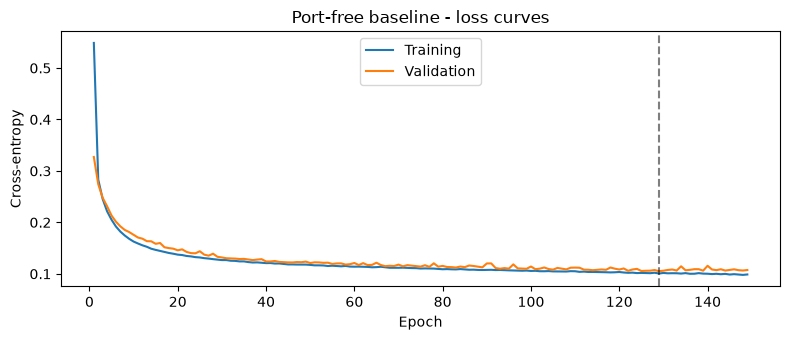

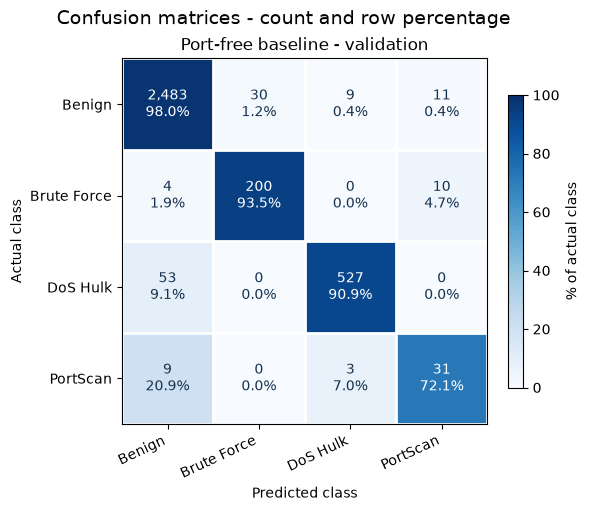

In [188]:
epochs_4 = np.arange(1, len(result_4["train"]) + 1)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(epochs_4, result_4["train"], label="Training")
ax.plot(epochs_4, result_4["val"], label="Validation")
ax.axvline(result_4["best_epoch"], color="black", linestyle="--", alpha=0.5)
ax.set(title="Port-free baseline - loss curves", xlabel="Epoch", ylabel="Cross-entropy")
ax.legend()
fig.tight_layout()
plt.show()
plot_confusion_2c([validation_4["confusion_matrix"]], ["Port-free baseline - validation"])

### Our interpretation

Our prediction holds: PortScan has the lowest F1 (0.6526) and recall (0.7209). We still detect **31/43** PortScan flows. Of the 12 misses, nine are predicted as Benign and three as DoS Hulk. There are also 21 false PortScan predictions, giving precision 0.5962.

Validation accuracy is 0.9617, but macro-F1 is 0.8682; accuracy alone hides the rare-class weakness. Early stopping occurs at epoch 149, and we restore epoch 129 (validation CE 0.10506). This is our unweighted port-free reference for the next comparisons.

### Task 4B - Class-weighted cross-entropy

We compute balanced weights from **training labels only**. Validation/test labels must not influence our training objective.

**Our prediction before training:** slightly lower accuracy, but higher macro-F1 and PortScan recall. Upweighting rare attacks may increase false alarms; PortScan precision is already 0.5962, so macro-F1 improvement is not guaranteed. We keep the model, initialization, data, optimizer and stopping settings fixed and change only the loss.

In [189]:
from sklearn.utils.class_weight import compute_class_weight

HP_4B = HP_4.copy()
classes_4b = np.arange(len(label_encoder_3b.classes_))
weights_4b = compute_class_weight(class_weight="balanced", classes=classes_4b, y=y_train_3b)
print(pd.DataFrame({"Train samples": np.bincount(y_train_3b), "Loss weight": weights_4b},
                   index=label_encoder_3b.classes_).round(4).to_string())

             Train samples  Loss weight
Benign               11821       0.3326
Brute Force            999       3.9357
DoS Hulk              2708       1.4519
PortScan               199      19.7575


In [190]:
random.seed(HP_4B["seed"])
np.random.seed(HP_4B["seed"])
torch.manual_seed(HP_4B["seed"])
train_loader_4b = DataLoader(train_loader_4.dataset, batch_size=HP_4B["batch_size"],
                            shuffle=True, generator=torch.Generator().manual_seed(HP_4B["seed"]))
val_loader_4b = DataLoader(val_loader_4.dataset, batch_size=HP_4B["batch_size"],
                          shuffle=False, generator=torch.Generator().manual_seed(HP_4B["seed"]))
model_4b = nn.Sequential(
    nn.Linear(X_train_std_3b.shape[1], HP_4B["hidden_size"]), nn.ReLU(),
    nn.Linear(HP_4B["hidden_size"], len(classes_4b)),
).to(device_4)
criterion_4b = nn.CrossEntropyLoss(weight=torch.tensor(weights_4b, dtype=torch.float32, device=device_4))
optimizer_4b = torch.optim.AdamW(model_4b.parameters(), lr=HP_4B["lr"], weight_decay=HP_4B["weight_decay"])
result_4b = fit(model_4b, optimizer_4b, train_loader_4b, val_loader_4b,
                max_epochs=HP_4B["max_epochs"], patience=HP_4B["patience"],
                min_delta=HP_4B["min_delta"], verbose=False, criterion=criterion_4b)
if result_4b["best_epoch"] == 0:
    raise RuntimeError("No finite validation checkpoint for the weighted model")
print(f"Epochs: {len(result_4b['train'])}; best epoch: {result_4b['best_epoch']}")
print(f"Best weighted validation CE: {result_4b['best_loss']:.5f}")
print(f"Training + epoch validation: {result_4b['seconds']:.2f} s")

Early stopping at epoch 137
Epochs: 137; best epoch: 117
Best weighted validation CE: 0.18363
Training + epoch validation: 28.40 s


In [191]:
validation_4b = evaluate_2c(model_4b, X_val_std_3b, y_val_3b,
                             "Task 4B - weighted model, validation")
comparison_4b = pd.DataFrame({"Unweighted": validation_4["metrics"],
                              "Weighted": validation_4b["metrics"]}).T
print("\nValidation comparison (loss: ordinary unweighted CE for both models)")
print(comparison_4b.round(5).to_string())
per_class_4b = pd.DataFrame({
    f"{name} {metric}": {cls: result["report"][cls][metric] for cls in label_encoder_3b.classes_}
    for name, result in {"Unweighted": validation_4, "Weighted": validation_4b}.items()
    for metric in ("precision", "recall", "f1-score")
})
print("\nPer-class validation comparison")
print(per_class_4b.round(4).to_string())
accuracy_change_4b = validation_4b["metrics"]["accuracy"] - validation_4["metrics"]["accuracy"]
macro_change_4b = validation_4b["metrics"]["macro_f1"] - validation_4["metrics"]["macro_f1"]
print(f"Accuracy change: {accuracy_change_4b:+.4f} ({100 * accuracy_change_4b:+.2f} pp)")
print(f"Macro-F1 change: {macro_change_4b:+.4f} ({100 * macro_change_4b:+.2f} pp)")
print("Same direction:", "yes" if accuracy_change_4b * macro_change_4b > 0 else
      "no" if accuracy_change_4b * macro_change_4b < 0 else "one or both unchanged")


Task 4B - weighted model, validation
              precision    recall  f1-score   support

      Benign     0.9873    0.9175    0.9511      2533
 Brute Force     0.7769    0.9439    0.8523       214
    DoS Hulk     0.8752    0.8948    0.8849       580
    PortScan     0.2515    0.9535    0.3981        43

    accuracy                         0.9157      3370
   macro avg     0.7227    0.9274    0.7716      3370
weighted avg     0.9452    0.9157    0.9264      3370

loss               0.20914
accuracy           0.91573
macro_precision    0.72273
macro_recall       0.92743
macro_f1           0.77160
weighted_f1        0.92638

Validation comparison (loss: ordinary unweighted CE for both models)
               loss  accuracy  macro_precision  macro_recall  macro_f1  weighted_f1
Unweighted  0.10506   0.96172          0.85439       0.88610   0.86815      0.96212
Weighted    0.20914   0.91573          0.72273       0.92743   0.77160      0.92638

Per-class validation comparison
          

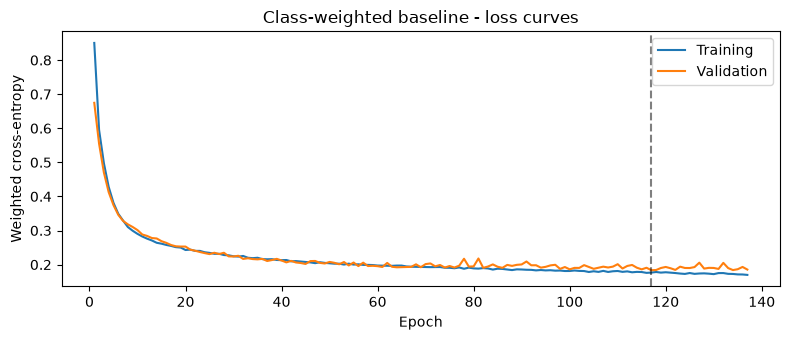

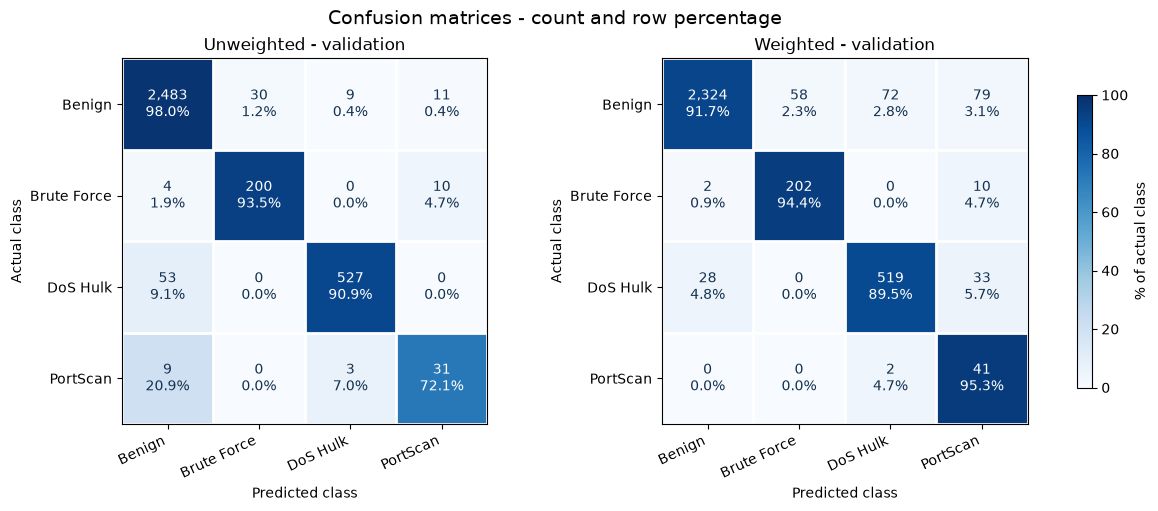

In [192]:
fig, ax = plt.subplots(figsize=(8, 3.5))
epochs_4b = np.arange(1, len(result_4b["train"]) + 1)
ax.plot(epochs_4b, result_4b["train"], label="Training")
ax.plot(epochs_4b, result_4b["val"], label="Validation")
ax.axvline(result_4b["best_epoch"], color="black", linestyle="--", alpha=0.5)
ax.set(title="Class-weighted baseline - loss curves", xlabel="Epoch", ylabel="Weighted cross-entropy")
ax.legend()
fig.tight_layout()
plt.show()
plot_confusion_2c([validation_4["confusion_matrix"], validation_4b["confusion_matrix"]],
                  ["Unweighted - validation", "Weighted - validation"])

### Our result and metric choice

Accuracy and macro-F1 both fall (0.96172 -> 0.91573 and 0.86815 -> 0.77160). Our expected macro-F1 improvement is not confirmed. PortScan recall rises from 31/43 to 41/43, but precision falls from 0.5962 to 0.2515: false PortScan predictions increase from 21 to 122.

We prioritize macro-F1 while checking rare-class recall and false alarms. We keep the unweighted run 8 as our port-free reference; balanced weights increase recall at too high a precision cost here.

## Task 5 - Hyperparameters

## Task 6 - Optimizations